In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

df=pd.read_csv("train.csv",encoding="latin1")

In [7]:
df.shape

(1366, 3)

In [8]:
df.head()

,Item ID,Sentiment,SentimentText
0,1,0,"@RailMinIndia My PNR is 8348062961, I am in wa..."
1,2,0,@sureshpprabhu @RailMinIndia AC not working in...
2,3,0,@RailMinIndia I'm traveling to chennai by trai...
3,4,5,@RailMinIndia irctc is not responding at the t...
4,5,7,@DRMbhopal @RailMinIndia @sanjaygupta2012 @drm...


In [9]:
df.tail()

,Item ID,Sentiment,SentimentText
1361,1362,5,@RailMinIndia An aged lady has been alloted up...
1362,1363,1,"aggressive copassengers, need of immediate cha..."
1363,1364,0,@RailMinIndia no water in coach...please do so...
1364,1365,3,@RailMinIndia @sureshpprabhu While travelling ...
1365,1366,6,https://t.co/f27P3FSDcJ @PMOIndia @narendramodi


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1366 entries, 0 to 1365
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Item ID        1366 non-null   int64 
 1   Sentiment      1366 non-null   int64 
 2   SentimentText  1366 non-null   object
dtypes: int64(2), object(1)
memory usage: 32.1+ KB


In [11]:
df.describe(include="all")

,Item ID,Sentiment,SentimentText
count,1366.000000,1366.000000,1366
unique,NaN,NaN,1353
top,NaN,NaN,@DArpitBhargava @WesternRly @sureshpprabhu @Pi...
freq,NaN,NaN,2
mean,683.500000,3.563690,NaN
std,394.474545,2.291241,NaN
min,1.000000,0.000000,NaN
25%,342.250000,1.000000,NaN
50%,683.500000,4.000000,NaN
75%,1024.750000,5.000000,NaN


In [12]:
df.isnull().sum()

Item ID          0
Sentiment        0
SentimentText    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['SentimentText'].duplicated().sum()

np.int64(13)

In [15]:
duplicates = df[df["SentimentText"].duplicated(keep=False)]

duplicates.sort_values("SentimentText")[[
    "Item ID",
    "Sentiment",
    "SentimentText"
]]

,Item ID,Sentiment,SentimentText
154,155,7,@DArpitBhargava @WesternRly @sureshpprabhu @Pi...
879,880,1,@DArpitBhargava @WesternRly @sureshpprabhu @Pi...
510,511,0,@DRMbhopal @satyavsingh @RailMinIndia Sorry fo...
163,164,7,@DRMbhopal @satyavsingh @RailMinIndia Sorry fo...
252,253,1,@IRCTC_Ltd @RailMinIndia @RailMinIndia Take ...
863,864,6,@IRCTC_Ltd @RailMinIndia @RailMinIndia Take ...
217,218,3,@RailMinIndia @PiyushGoyal @RailwayNorthern My...
57,58,4,@RailMinIndia @PiyushGoyal @RailwayNorthern My...
868,869,0,@RailMinIndia @drmnfr_lmg @IR_ENHM till now no...
94,95,6,@RailMinIndia @drmnfr_lmg @IR_ENHM till now no...


In [16]:
df = df.drop_duplicates(
    subset="SentimentText",
    keep="first"
).reset_index(drop=True)

In [17]:
print("New dataset shape:", df.shape)
print("Duplicate complaint texts:",
      df["SentimentText"].duplicated().sum())

New dataset shape: (1353, 3)
Duplicate complaint texts: 0


In [18]:
print(df["Sentiment"].value_counts().sort_index())

Sentiment
0    276
1     82
2     31
3    156
4    217
5    298
6    203
7     90
Name: count, dtype: int64


In [19]:
for value in sorted(df["Sentiment"].unique()):
    print("\n========== Sentiment", value, "==========")
    print(
        df[df["Sentiment"] == value]["SentimentText"]
        .head(5)
        .to_string(index=False)
    )


========== Sentiment 0 ==========
@RailMinIndia My PNR is 8348062961, I am in way...
@sureshpprabhu @RailMinIndia AC not working in ...
@RailMinIndia I'm traveling to chennai by train...
@RailMinIndia @mumbairailusers Dirty water flow...
@RailMinIndia #Swatch Bharat Abhiyaan# Train st...

========== Sentiment 1 ==========
@RailMinIndia @YourSKD Sir, FIR lodged by GRP/B...
@RailMinIndia @sureshpprabhu My bro lost his lu...
@sureshpprabhu @RailMinIndia @IRCTC_Ltd plz hlp...
@RailMinIndia @Parashuram_vns Sir, FIR lodged b...
@RailMinIndia  Sir, We lost a mobile with beari...

========== Sentiment 2 ==========
@sureshpprabhu @RailMinIndia I Request for doct...
@RailMinIndia we are traveling in 19806 we have...
@RailMinIndia need medical assistance in train ...
@RailMinIndia  my wife is travelling by 12310 r...
@RailMinIndia @RailMinIndia Sir A couple travel...

========== Sentiment 3 ==========
@RailMinIndia still vendors are selling local l...
@RailMinIndia Sir, ?? ?????? ????? ?????? ??

In [20]:
sentiment_counts = df["Sentiment"].value_counts().sort_index()

print(sentiment_counts)

Sentiment
0    276
1     82
2     31
3    156
4    217
5    298
6    203
7     90
Name: count, dtype: int64


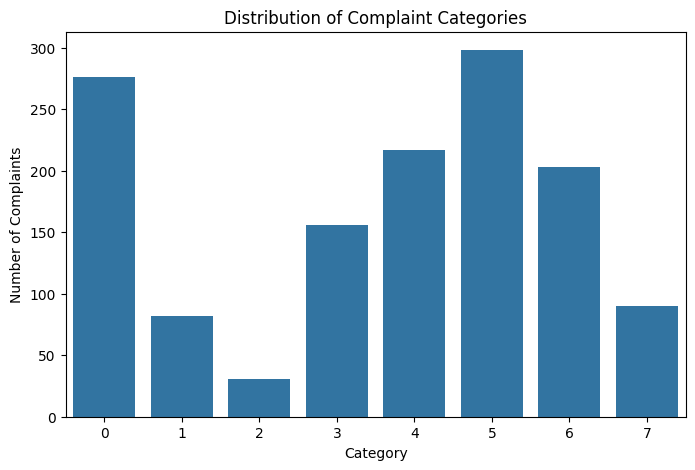

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Sentiment",
    order=sorted(df["Sentiment"].unique())
)

plt.title("Distribution of Complaint Categories")
plt.xlabel("Category")
plt.ylabel("Number of Complaints")

plt.show()

In [22]:
category_percentage = (
    df["Sentiment"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(category_percentage.round(2))

Sentiment
0    20.40
1     6.06
2     2.29
3    11.53
4    16.04
5    22.03
6    15.00
7     6.65
Name: proportion, dtype: float64


In [23]:
for value in sorted(df["Sentiment"].unique()):
    print(f"\n{'='*70}")
    print(f"CATEGORY {value}")
    print(f"{'='*70}")
    
    samples = df[df["Sentiment"] == value]["SentimentText"].sample(
        min(10, len(df[df["Sentiment"] == value])),
        random_state=42
    )
    
    for i, text in enumerate(samples, 1):
        print(f"{i}. {text}")


CATEGORY 0
1. @railminindia @sureshpprabhu  can't even use the restroom as the corridor is full of Unreserved passengers. Please help ASAP.2/2
2. @RailMinIndia travelling in 09456 frm gandhidham to surat.  There is no water in B1, paying more thn normal fare. how it is special train??
3. @RailMinIndia @sureshpprabhu Sir my train no. 12186 coach no. Is S2,6 is and my seat is near toilet and its very dirty and nasty.
4. @RailMinIndia there is leakage of roof of train no. 16346 coach no B4 at toilet and near toilet area. Repair it. https://t.co/rcDA52wbZw
5. @RailMinIndia PNR:6253063718,TRAIN:15909 with 2 children train fully occupied by unauthorized passengers that we cannt able to go to toilet
6. @RailMinIndia Dear sir, I am traveling in awadh assam exp PNR 2817784641, there is no water in washroom and so dirty coach..
7. @RailMinIndia - extremely dirty bathrooms in ac 2 tier coaches of 12552. The overall maintenance and cleanliness seems below par
8. @sureshpprabhu @RailMinIndia at th

In [24]:
retweet_count = df["SentimentText"].str.startswith(
    "RT", na=False
).sum()

print("Retweets:", retweet_count)
print("Percentage:", round(retweet_count / len(df) * 100, 2), "%")

Retweets: 62
Percentage: 4.58 %


NOISE ANALYSIS

Check Retweets

In [25]:
rt_pattern_count = df["SentimentText"].str.contains(
    r"\bRT\b",
    case=False,
    regex=True,
    na=False
).sum()

print("Tweets containing RT:", rt_pattern_count)

Tweets containing RT: 64


Check URLs/

In [26]:
url_count = df["SentimentText"].str.contains(
    r"http\S+|www\S+",
    case=False,
    regex=True,
    na=False
).sum()

print("Complaints containing URLs:", url_count)
print("Percentage:", round(url_count / len(df) * 100, 2), "%")

Complaints containing URLs: 285
Percentage: 21.06 %


Check @mentions

In [27]:
mention_count = df["SentimentText"].str.contains(
    r"@\w+",
    regex=True,
    na=False
).sum()

print("Texts containing @mentions:", mention_count)
print("Percentage:", round(mention_count / len(df) * 100, 2), "%")

Texts containing @mentions: 1293
Percentage: 95.57 %


Check hashtags

In [28]:
hashtag_count = df["SentimentText"].str.contains(
    r"#\w+",
    regex=True,
    na=False
).sum()

print("Texts containing hashtags:", hashtag_count)
print("Percentage:", round(hashtag_count / len(df) * 100, 2), "%")

Texts containing hashtags: 74
Percentage: 5.47 %


Check very short texts

In [29]:
df["word_count"] = df["SentimentText"].str.split().str.len()

print(df["word_count"].describe())

count    1353.000000
mean       17.705839
std         5.018378
min         2.000000
25%        15.000000
50%        18.000000
75%        21.000000
max        29.000000
Name: word_count, dtype: float64


In [30]:
print(
    df[df["word_count"] <= 5][
        ["Sentiment", "SentimentText", "word_count"]
    ].to_string(index=False)
)

 Sentiment                                                             SentimentText  word_count
         5                                          @RailMinIndia PNR NO. 6107451949           4
         6                           @drmdelhi @RailMinIndia @srdomchgdli No reply..           5
         5                                              @drmadiwr PNR No -2720271036           4
         6                                RT @sureshpprabhu: https://t.co/06uwLS5m7J           3
         6                                       @RailMinIndia Thanks for your reply           5
         6        @IRCTC_Ltd @RailMinIndia @PiyushGoyalOffc  https://t.co/pI0q6MyzyH           4
         6              @amt10x @RailMinIndia @nerailwaygkp  https://t.co/mWqazSZhv9           4
         6                                       @NashikNews https://t.co/u8sL0GURHI           2
         6                    @atulyendepatil @TajinderBagga https://t.co/e69QtW6PvK           3
         6                    

Check Common Words

In [31]:
from collections import Counter
import re

all_text = " ".join(df["SentimentText"].astype(str))

words = re.findall(r"\b[a-zA-Z]+\b", all_text.lower())

word_counts = Counter(words)

print(word_counts.most_common(30))

[('railminindia', 1215), ('in', 474), ('no', 465), ('is', 450), ('to', 425), ('sureshpprabhu', 412), ('train', 404), ('t', 346), ('the', 294), ('co', 290), ('https', 288), ('of', 272), ('for', 262), ('pnr', 250), ('not', 242), ('i', 229), ('and', 224), ('sir', 214), ('at', 174), ('ticket', 153), ('on', 149), ('water', 147), ('coach', 147), ('a', 143), ('my', 142), ('from', 136), ('by', 132), ('help', 129), ('late', 120), ('but', 111)]


Remove URLS

In [32]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"http\S+|www\S+",
    "",
    regex=True
)

In [33]:
url_count_after = df["SentimentText"].str.contains(
    r"http\S+|www\S+",
    case=False,
    regex=True,
    na=False
).sum()

print("URLs remaining:", url_count_after)

URLs remaining: 0


Remove mentions

In [34]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"@\w+",
    "",
    regex=True
)

In [35]:
mention_count_after = df["SentimentText"].str.contains(
    r"@\w+",
    regex=True,
    na=False
).sum()

print("Mentions remaining:", mention_count_after)

Mentions remaining: 0


Remove the RT marker

In [36]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\bRT\b",
    "",
    regex=True,
    case=False
)

Handle HTML entities

In [37]:
import html

df["SentimentText"] = df["SentimentText"].apply(
    lambda x: html.unescape(x)
)

Normalize whitespace

In [38]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

In [39]:
df["SentimentText"].head(20)

0     My PNR is 8348062961, I am in way but there is...
1     AC not working in prayag lucknow intercity tod...
2     I'm traveling to chennai by train 16102 coach ...
3     irctc is not responding at the time of tatkal ...
4                 Matter notified to concerned official
5     If you can't give justice to graduate engineer...
6     wrkout smthng tht cn hlp trains to run on righ...
7     Dirty water flowing ftm blower of local coach ...
8     Enter to win $150 Amazon Gift Card! #Books #PN...
9     still vendors are selling local local products...
10    please update the status of today 12141 LTT PP...
11    #Swatch Bharat Abhiyaan# Train stops at kozhik...
12    my reserved ticket was been allotted to RAC pa...
13          update:- today intercity 12930 late 16 min?
14    TRAIN NO 12656 THERE IS NO PROPER WATER SERVIC...
15    The Google i1 button is used 5 billion times p...
16    Sir, ?? ?????? ????? ?????? ?? ?????????? ?? 6...
17    Train has departed Varanasi and will be re

Handling Numbers

In [40]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\b\d+\b",
    "",
    regex=True
)

In [41]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\bPNR\b",
    "",
    regex=True,
    case=False
)

In [42]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

In [43]:
df["SentimentText"].head(20)

0     My is , I am in way but there is no water in t...
1     AC not working in prayag lucknow intercity tod...
2     I'm traveling to chennai by train coach S4-. M...
3     irctc is not responding at the time of tatkal ...
4                 Matter notified to concerned official
5     If you can't give justice to graduate engineer...
6     wrkout smthng tht cn hlp trains to run on righ...
7     Dirty water flowing ftm blower of local coach ...
8     Enter to win $ Amazon Gift Card! #Books # #Urb...
9     still vendors are selling local local products...
10    please update the status of today LTT PPTA EXP...
11    #Swatch Bharat Abhiyaan# Train stops at kozhik...
12    my reserved ticket was been allotted to RAC pa...
13                   update:- today intercity late min?
14    TRAIN NO THERE IS NO PROPER WATER SERVICE IN T...
15    The Google i1 button is used billion times day...
16    Sir, ?? ?????? ????? ?????? ?? ?????????? ?? ?...
17    Train has departed Varanasi and will be re

In [44]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\b(my|the)?\s*(pnr|p\.n\.r)\s*(is|no|number)?\b",
    "",
    regex=True,
    case=False
)

In [45]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\bmy\s+is\b",
    "",
    regex=True,
    case=False
)

In [46]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

Handling Hasthtags and Punctuations

In [47]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"#",
    "",
    regex=True
)

In [48]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"[^\w\s']",
    " ",
    regex=True
)

In [49]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

In [50]:
df["SentimentText"] = df["SentimentText"].str.lower()

In [51]:
df["SentimentText"].head(20)

0     i am in way but there is no water in toilet an...
1     ac not working in prayag lucknow intercity tod...
2     i'm traveling to chennai by train coach s4 my ...
3     irctc is not responding at the time of tatkal ...
4                 matter notified to concerned official
5     if you can't give justice to graduate engineer...
6     wrkout smthng tht cn hlp trains to run on righ...
7     dirty water flowing ftm blower of local coach ...
8     enter to win amazon gift card books urbanfanta...
9     still vendors are selling local local products...
10    please update the status of today ltt ppta exp...
11    swatch bharat abhiyaan train stops at kozhikod...
12    my reserved ticket was been allotted to rac pa...
13                      update today intercity late min
14    train no there is no proper water service in t...
15    the google i1 button is used billion times day...
16                                      sir water point
17    train has departed varanasi and will be re

In [52]:
df["SentimentText"] = df["SentimentText"].str.replace(
    r"\b(train|coach|seat)\s+(number|no)\b",
    "",
    regex=True,
    case=False
)
df["SentimentText"] = (
    df["SentimentText"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [53]:
sample_text = df["SentimentText"].sample(
    30,
    random_state=42
)

for i, text in enumerate(sample_text, 1):
    print(f"{i}. {text}")

1. pls tell me t no will originate today from bcy or not
2. sorry the tweet received from doesn't contain your complaint
3. train status running yet chart not prepared waiting for confirmation since longfacing trouble
4. bought 1st class ticket of western rly local train board oldest train running on d li
5. railminindia dear sir no from chapra to new bongaigaon still showing waiting list iâ
6. i am sure that railwys only care abt posting on twittr and fb i posted my issue many times now and no reply
7. tweet no first mumbai showers have made havoc as usual train stuck at matunga made in india
8. sir think of changing menu in ndls bct nzm bct rajdhani since long same veg nv meal snacks r being served
9. ben sending msgs the lst night to recvd no reply am i wrong to ask fr ny refund
10. stuck between bijwasan ggn regular late running train
11. irctc emergency plz help
12. the first class coupes in the ranchi hatia express are very old and poor air conditioning they should be replac
13. 

In [54]:
empty_text = df["SentimentText"].str.strip().eq("").sum()
print("Empty complaints:", empty_text)

Empty complaints: 38


In [55]:
df = df[df["SentimentText"].str.strip() != ""].copy()

In [56]:
df["word_count"] = df["SentimentText"].str.split().str.len()

print(df["word_count"].describe())

count    1315.000000
mean       14.952091
std         5.185448
min         1.000000
25%        12.000000
50%        15.000000
75%        19.000000
max        29.000000
Name: word_count, dtype: float64


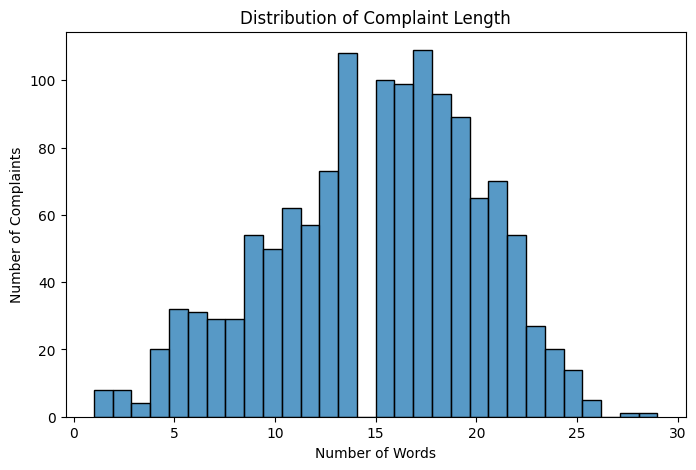

In [57]:
plt.figure(figsize=(8, 5))

sns.histplot(df["word_count"], bins=30)

plt.title("Distribution of Complaint Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Complaints")

plt.show()

In [58]:
import re
from collections import Counter

df["tokens"] = df["SentimentText"].apply(
    lambda x: re.findall(r"\b[a-zA-Z']+\b", x)
)

In [59]:
df[["SentimentText", "tokens"]].head()

,SentimentText,tokens
0,i am in way but there is no water in toilet an...,"[i, am, in, way, but, there, is, no, water, in..."
1,ac not working in prayag lucknow intercity tod...,"[ac, not, working, in, prayag, lucknow, interc..."
2,i'm traveling to chennai by train coach s4 my ...,"[i'm, traveling, to, chennai, by, train, coach..."
3,irctc is not responding at the time of tatkal ...,"[irctc, is, not, responding, at, the, time, of..."
4,matter notified to concerned official,"[matter, notified, to, concerned, official]"


In [60]:
all_words = []

for tokens in df["tokens"]:
    all_words.extend(tokens)

word_counts = Counter(all_words)

top_words = word_counts.most_common(20)

print(top_words)

[('in', 474), ('is', 446), ('to', 425), ('no', 324), ('the', 294), ('of', 272), ('train', 271), ('for', 262), ('not', 242), ('and', 224), ('sir', 214), ('i', 213), ('at', 174), ('ticket', 152), ('on', 149), ('water', 147), ('a', 143), ('my', 138), ('from', 136), ('by', 132)]


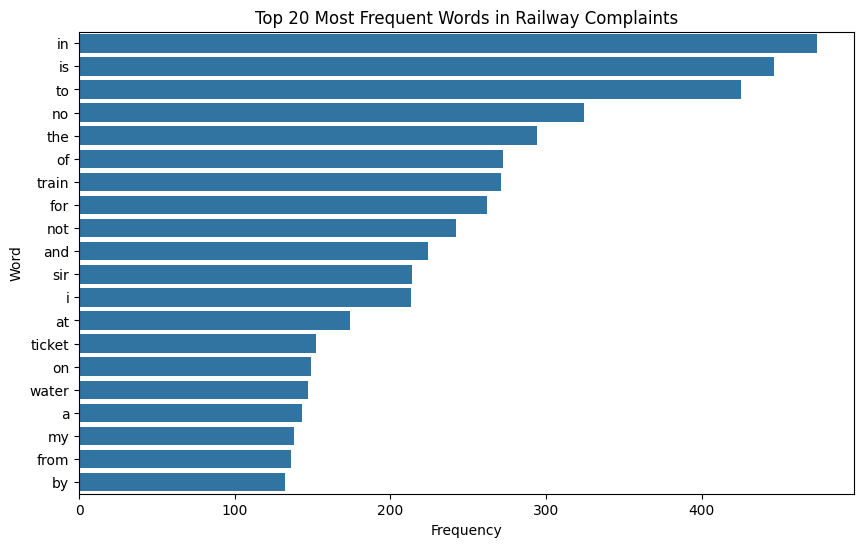

In [61]:
words = [word for word, count in top_words]
counts = [count for word, count in top_words]

plt.figure(figsize=(10, 6))

sns.barplot(
    x=counts,
    y=words
)

plt.title("Top 20 Most Frequent Words in Railway Complaints")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

In [62]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

In [63]:
stop_words = stop_words - {
    "no",
    "not",
    "nor",
    "never"
}

In [64]:
meaningful_words = []

for tokens in df["tokens"]:
    for word in tokens:
        if word not in stop_words:
            meaningful_words.append(word)

meaningful_counts = Counter(meaningful_words)

top_meaningful = meaningful_counts.most_common(20)

print(top_meaningful)

[('no', 324), ('train', 271), ('not', 242), ('sir', 214), ('ticket', 152), ('water', 147), ('coach', 129), ('help', 129), ('late', 120), ('please', 103), ('plz', 90), ('railway', 81), ('station', 75), ('working', 71), ('ac', 67), ('tatkal', 66), ('food', 64), ('time', 58), ('express', 58), ('n', 56)]


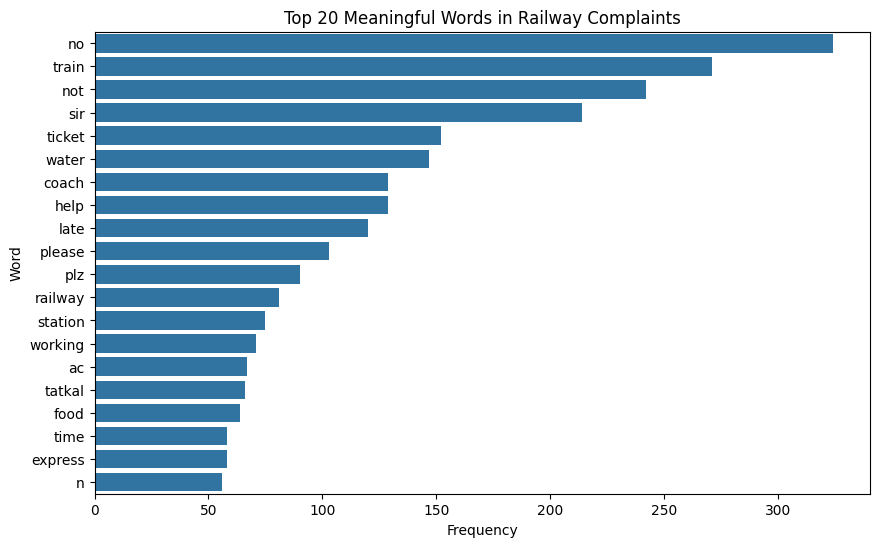

In [65]:
words = [word for word, count in top_meaningful]
counts = [count for word, count in top_meaningful]

plt.figure(figsize=(10, 6))

sns.barplot(x=counts, y=words)

plt.title("Top 20 Meaningful Words in Railway Complaints")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

In [66]:
custom_stopwords = stop_words - {
    "no",
    "not",
    "nor",
    "never"
}
custom_noise_words = {
    "sir",
    "please"
}

In [67]:
from collections import Counter

for category in sorted(df["Sentiment"].unique()):
    
    category_text = df[df["Sentiment"] == category]["tokens"]
    
    words = []
    
    for tokens in category_text:
        for word in tokens:
            if word not in custom_stopwords:
                words.append(word)
    
    top_category_words = Counter(words).most_common(10)
    
    print(f"\nCategory {category}")
    print(top_category_words)


Category 0
[('no', 119), ('coach', 94), ('water', 89), ('not', 89), ('train', 68), ('working', 61), ('ac', 48), ('toilet', 39), ('dirty', 38), ('toilets', 34)]

Category 1
[('no', 36), ('grp', 27), ('sir', 21), ('fir', 19), ('u', 17), ('lodged', 16), ('lost', 15), ('vide', 14), ('train', 14), ('cr', 13)]

Category 2
[('medical', 12), ('help', 11), ('no', 8), ('need', 8), ('train', 7), ('assistance', 6), ('sir', 5), ('coach', 4), ('plz', 4), ('old', 4)]

Category 3
[('food', 55), ('water', 54), ('no', 34), ('train', 31), ('not', 29), ('sir', 28), ('rs', 28), ('vendor', 21), ('pantry', 20), ('selling', 19)]

Category 4
[('late', 115), ('train', 110), ('no', 46), ('hours', 36), ('not', 31), ('running', 30), ('hrs', 29), ('sir', 26), ('time', 24), ('delayed', 21)]

Category 5
[('ticket', 140), ('sir', 67), ('not', 64), ('tatkal', 64), ('no', 61), ('tickets', 50), ('help', 45), ('irctc', 43), ('please', 31), ('train', 31)]

Category 6
[('thanks', 25), ('railway', 21), ('sir', 20), ('no', 1

In [68]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

# Preserve negation words because they are important
important_words = {
    "no",
    "not",
    "nor",
    "never"
}

custom_stopwords = stop_words - important_words

# Dataset-specific words that don't help identify complaint topics
custom_stopwords.update({
    "sir",
    "please"
})

print("Total custom stopwords:", len(custom_stopwords))

Total custom stopwords: 197


In [69]:
slang_map = {
    "pls": "please",
    "plz": "please",
    "hlp": "help",
    "tkt": "ticket",
    "bcoz": "because",
    "abt": "about",
    "fr": "for",
    "rlys": "railways",
    "recvd": "received",
    "n": "and",
    "u": "you",
    "ur": "your",
    "smthng": "something",
    "wrkout": "workout",
    "tht": "that",
    "cn": "can",
    "r": "are",
    "w": "with",
    "yur": "your",
    "ny": "any",
    "msg": "message",
    "msgs": "messages",
    "recieve": "receive",
    "recieved": "received",
    "askd": "asked",
    "gav": "gave",
    "b": "be",
    "bcum": "become"
}

In [70]:
def normalize_tokens(tokens):
    return [
        slang_map.get(word, word)
        for word in tokens
    ]

df["tokens"] = df["tokens"].apply(normalize_tokens)

In [71]:
df[["SentimentText", "tokens"]].head(20)

,SentimentText,tokens
0,i am in way but there is no water in toilet an...,"[i, am, in, way, but, there, is, no, water, in..."
1,ac not working in prayag lucknow intercity tod...,"[ac, not, working, in, prayag, lucknow, interc..."
2,i'm traveling to chennai by train coach s4 my ...,"[i'm, traveling, to, chennai, by, train, coach..."
3,irctc is not responding at the time of tatkal ...,"[irctc, is, not, responding, at, the, time, of..."
4,matter notified to concerned official,"[matter, notified, to, concerned, official]"
5,if you can't give justice to graduate engineer...,"[if, you, can't, give, justice, to, graduate, ..."
6,wrkout smthng tht cn hlp trains to run on righ...,"[workout, something, that, can, help, trains, ..."
7,dirty water flowing ftm blower of local coach ...,"[dirty, water, flowing, ftm, blower, of, local..."
8,enter to win amazon gift card books urbanfanta...,"[enter, to, win, amazon, gift, card, books, ur..."
9,still vendors are selling local local products...,"[still, vendors, are, selling, local, local, p..."


In [72]:
def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in custom_stopwords
    ]

df["tokens"] = df["tokens"].apply(remove_stopwords)

In [73]:
df[["SentimentText", "tokens"]].head(20)

,SentimentText,tokens
0,i am in way but there is no water in toilet an...,"[way, no, water, toilet, mess, everywhere, coa..."
1,ac not working in prayag lucknow intercity tod...,"[ac, not, working, prayag, lucknow, intercity,..."
2,i'm traveling to chennai by train coach s4 my ...,"[traveling, chennai, train, coach, berth, dirt..."
3,irctc is not responding at the time of tatkal ...,"[irctc, not, responding, time, tatkal, booking]"
4,matter notified to concerned official,"[matter, notified, concerned, official]"
5,if you can't give justice to graduate engineer...,"[can't, give, justice, graduate, engineers, on..."
6,wrkout smthng tht cn hlp trains to run on righ...,"[workout, something, help, trains, run, right,..."
7,dirty water flowing ftm blower of local coach ...,"[dirty, water, flowing, ftm, blower, local, co..."
8,enter to win amazon gift card books urbanfanta...,"[enter, win, amazon, gift, card, books, urbanf..."
9,still vendors are selling local local products...,"[still, vendors, selling, local, local, produc..."


In [74]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\91942\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\91942\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [75]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

In [76]:
def lemmatize_tokens(tokens):
    return [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

df["tokens"] = df["tokens"].apply(lemmatize_tokens)

In [77]:
df[["SentimentText", "tokens"]].head(20)

,SentimentText,tokens
0,i am in way but there is no water in toilet an...,"[way, no, water, toilet, mess, everywhere, coa..."
1,ac not working in prayag lucknow intercity tod...,"[ac, not, working, prayag, lucknow, intercity,..."
2,i'm traveling to chennai by train coach s4 my ...,"[traveling, chennai, train, coach, berth, dirt..."
3,irctc is not responding at the time of tatkal ...,"[irctc, not, responding, time, tatkal, booking]"
4,matter notified to concerned official,"[matter, notified, concerned, official]"
5,if you can't give justice to graduate engineer...,"[can't, give, justice, graduate, engineer, one..."
6,wrkout smthng tht cn hlp trains to run on righ...,"[workout, something, help, train, run, right, ..."
7,dirty water flowing ftm blower of local coach ...,"[dirty, water, flowing, ftm, blower, local, co..."
8,enter to win amazon gift card books urbanfanta...,"[enter, win, amazon, gift, card, book, urbanfa..."
9,still vendors are selling local local products...,"[still, vendor, selling, local, local, product..."


In [78]:
df["clean_text"] = df["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

In [79]:
df[["SentimentText", "clean_text"]].head(20)

,SentimentText,clean_text
0,i am in way but there is no water in toilet an...,way no water toilet mess everywhere coach prov...
1,ac not working in prayag lucknow intercity tod...,ac not working prayag lucknow intercity today ...
2,i'm traveling to chennai by train coach s4 my ...,traveling chennai train coach berth dirty one ...
3,irctc is not responding at the time of tatkal ...,irctc not responding time tatkal booking
4,matter notified to concerned official,matter notified concerned official
5,if you can't give justice to graduate engineer...,can't give justice graduate engineer one thing...
6,wrkout smthng tht cn hlp trains to run on righ...,workout something help train run right time ma...
7,dirty water flowing ftm blower of local coach ...,dirty water flowing ftm blower local coach aft...
8,enter to win amazon gift card books urbanfanta...,enter win amazon gift card book urbanfantasy r...
9,still vendors are selling local local products...,still vendor selling local local product like ...


Final quality check

In [80]:
print("Original text:")
print(df["SentimentText"].iloc[0])

print("\nTokens:")
print(df["tokens"].iloc[0])

print("\nFinal clean text:")
print(df["clean_text"].iloc[0])

Original text:
i am in way but there is no water in toilet and mess is everywhere in coach please provide basic facil

Tokens:
['way', 'no', 'water', 'toilet', 'mess', 'everywhere', 'coach', 'provide', 'basic', 'facil']

Final clean text:
way no water toilet mess everywhere coach provide basic facil


In [81]:
for i in [0, 1, 5, 7, 12, 18]:
    print(f"\n--- Complaint {i} ---")
    print("Before:", df["SentimentText"].iloc[i])
    print("After :", df["clean_text"].iloc[i])


--- Complaint 0 ---
Before: i am in way but there is no water in toilet and mess is everywhere in coach please provide basic facil
After : way no water toilet mess everywhere coach provide basic facil

--- Complaint 1 ---
Before: ac not working in prayag lucknow intercity today which departed from prayag at pm staff not helping us
After : ac not working prayag lucknow intercity today departed prayag pm staff not helping u

--- Complaint 5 ---
Before: if you can't give justice to graduate engineers then just do one thing at least stop recruiting b tech as sse
After : can't give justice graduate engineer one thing least stop recruiting tech sse

--- Complaint 7 ---
Before: dirty water flowing ftm blower of local coach aft 1st rain thane vashi
After : dirty water flowing ftm blower local coach aft rain thane vashi

--- Complaint 12 ---
Before: my reserved ticket was been allotted to rac passenger as we boarded from next station kindly please help
After : reserved ticket allotted rac pass

In [82]:
empty_clean = df["clean_text"].str.strip().eq("").sum()

print("Empty texts after preprocessing:", empty_clean)

Empty texts after preprocessing: 2


In [83]:
df[["SentimentText", "clean_text"]].head(10)

,SentimentText,clean_text
0,i am in way but there is no water in toilet an...,way no water toilet mess everywhere coach prov...
1,ac not working in prayag lucknow intercity tod...,ac not working prayag lucknow intercity today ...
2,i'm traveling to chennai by train coach s4 my ...,traveling chennai train coach berth dirty one ...
3,irctc is not responding at the time of tatkal ...,irctc not responding time tatkal booking
4,matter notified to concerned official,matter notified concerned official
5,if you can't give justice to graduate engineer...,can't give justice graduate engineer one thing...
6,wrkout smthng tht cn hlp trains to run on righ...,workout something help train run right time ma...
7,dirty water flowing ftm blower of local coach ...,dirty water flowing ftm blower local coach aft...
8,enter to win amazon gift card books urbanfanta...,enter win amazon gift card book urbanfantasy r...
9,still vendors are selling local local products...,still vendor selling local local product like ...


TF-IDF

In [84]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [85]:
tfidf = TfidfVectorizer(
    max_features=5000
)

In [86]:
X_tfidf = tfidf.fit_transform(df["clean_text"])

In [87]:
print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (1315, 3214)


In [88]:
feature_names = tfidf.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names[:50])

Number of features: 3214
['aadhar' 'aaj' 'aap' 'aapne' 'aati' 'aaye' 'aayen' 'ab' 'abhi' 'abhiyaan'
 'abhiyan' 'able' 'absolutely' 'absurd' 'abu' 'abundance' 'abusing' 'ac'
 'academic' 'accept' 'acceptance' 'accepted' 'accident' 'according'
 'account' 'accountable' 'accumulated' 'achieved' 'across' 'act' 'action'
 'active' 'activity' 'actual' 'add' 'addicated' 'additional' 'address'
 'adi' 'administration' 'adulterated' 'adv' 'adventure' 'advice' 'advise'
 'advised' 'afford' 'aft' 'aftr' 'age']


In [89]:
complaint_index = 0

row = X_tfidf[complaint_index].toarray().flatten()

top_indices = row.argsort()[-10:][::-1]

for i in top_indices:
    print(feature_names[i], row[i])

facil 0.42557396435604017
everywhere 0.42557396435604017
basic 0.37350575646986944
mess 0.36314533658232906
way 0.3467978068818966
provide 0.3237572578452573
toilet 0.2268849716019275
coach 0.1870680230113115
water 0.18664236569618936
no 0.1414157947915771


In [90]:
print("Matrix shape:", X_tfidf.shape)
print("Non-zero values:", X_tfidf.nnz)

Matrix shape: (1315, 3214)
Non-zero values: 11686


In [91]:
sparsity = 1 - (X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]))

print("Sparsity:", round(sparsity * 100, 2), "%")

Sparsity: 99.72 %


In [92]:
print("TF-IDF matrix shape:", X_tfidf.shape)
print("Number of features:", len(feature_names))
print("Non-zero values:", X_tfidf.nnz)
print("Sparsity:", round(sparsity * 100, 2), "%")

TF-IDF matrix shape: (1315, 3214)
Number of features: 3214
Non-zero values: 11686
Sparsity: 99.72 %


In [93]:
print(feature_names[:100])

['aadhar' 'aaj' 'aap' 'aapne' 'aati' 'aaye' 'aayen' 'ab' 'abhi' 'abhiyaan'
 'abhiyan' 'able' 'absolutely' 'absurd' 'abu' 'abundance' 'abusing' 'ac'
 'academic' 'accept' 'acceptance' 'accepted' 'accident' 'according'
 'account' 'accountable' 'accumulated' 'achieved' 'across' 'act' 'action'
 'active' 'activity' 'actual' 'add' 'addicated' 'additional' 'address'
 'adi' 'administration' 'adulterated' 'adv' 'adventure' 'advice' 'advise'
 'advised' 'afford' 'aft' 'aftr' 'age' 'aged' 'agent' 'agentsfeed'
 'aggarwal' 'aggressive' 'agr' 'agra' 'agricultural' 'ahmad' 'ahmdabad'
 'ahmedabad' 'ahraura' 'ai' 'aid' 'ailing' 'air' 'airconditioner'
 'airport' 'aisi' 'ajay' 'ajmer' 'al' 'ala' 'ald' 'aleppey' 'alert'
 'algorithm' 'ali' 'alipurduar' 'aljn' 'allahabad' 'allepey' 'allineed'
 'allocate' 'allocated' 'allocation' 'alloted' 'allotment' 'allotted'
 'allotting' 'allow' 'allowed' 'allowing' 'allowng' 'allows' 'allp'
 'alltwitter' 'almost' 'alone' 'alotted']


In [94]:
df.head()

,Item ID,Sentiment,SentimentText,word_count,tokens,clean_text
0,1,0,i am in way but there is no water in toilet an...,21,"[way, no, water, toilet, mess, everywhere, coa...",way no water toilet mess everywhere coach prov...
1,2,0,ac not working in prayag lucknow intercity tod...,18,"[ac, not, working, prayag, lucknow, intercity,...",ac not working prayag lucknow intercity today ...
2,3,0,i'm traveling to chennai by train coach s4 my ...,19,"[traveling, chennai, train, coach, berth, dirt...",traveling chennai train coach berth dirty one ...
3,4,5,irctc is not responding at the time of tatkal ...,10,"[irctc, not, responding, time, tatkal, booking]",irctc not responding time tatkal booking
4,5,7,matter notified to concerned official,5,"[matter, notified, concerned, official]",matter notified concerned official


In [95]:
empty_clean = df["clean_text"].str.strip().eq("").sum()

print("Empty texts after preprocessing:", empty_clean)

Empty texts after preprocessing: 2


In [96]:
empty_rows = df[df["clean_text"].str.strip().eq("")]

empty_rows[["Item ID", "SentimentText", "tokens", "clean_text"]]

,Item ID,SentimentText,tokens,clean_text
938,948,deâ,[],
1149,1159,498ajailsinnocent,[],


In [97]:
df = df[df["clean_text"].str.strip() != ""].copy()


In [98]:
print("Empty texts after preprocessing:", 
      df["clean_text"].str.strip().eq("").sum())

print("Final dataset shape:", df.shape)

Empty texts after preprocessing: 0
Final dataset shape: (1313, 6)


In [99]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(df["clean_text"])

In [100]:
print("TF-IDF matrix shape:", X_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))
print("Non-zero values:", X_tfidf.nnz)

TF-IDF matrix shape: (1313, 5000)
Number of features: 5000
Non-zero values: 15739


In [101]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:50])

['aadhar' 'aadhar no' 'aaj' 'aaj bhi' 'aap' 'aap aayen' 'aap bhi'
 'aap kya' 'aap mast' 'aap ya' 'aapne' 'aati' 'aati hai' 'aaye'
 'aaye plzz' 'aayen' 'aayen hain' 'ab' 'ab ho' 'ab mujhe' 'abhi'
 'abhi vendor' 'abhiyaan' 'abhiyaan train' 'abhiyan' 'abhiyan broker'
 'able' 'able answer' 'able book' 'able found' 'able get' 'able go'
 'able make' 'able visit' 'absolutely' 'abu' 'abu road' 'ac' 'ac coach'
 'ac not' 'ac ticket' 'ac working' 'accepted' 'accepted bribe'
 'accountable' 'act' 'action' 'action response' 'action taken' 'actual']


In [102]:
complaint_index = 0

row = X_tfidf[complaint_index].toarray().flatten()

top_indices = row.argsort()[-10:][::-1]

for i in top_indices:
    print(feature_names[i], round(row[i], 4))

facil 0.3454
everywhere coach 0.3454
everywhere 0.3454
coach provide 0.3454
basic 0.3032
mess 0.2948
way 0.2815
provide 0.2628
water toilet 0.2525
no water 0.1969


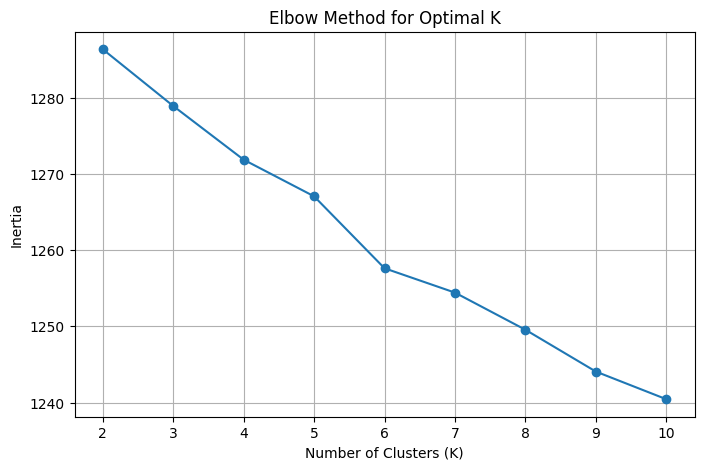

In [103]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store inertia values
inertia = []

# Test cluster counts from 2 to 10
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_tfidf)
    inertia.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [104]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_tfidf)

    score = silhouette_score(
        X_tfidf,
        labels,
        metric="euclidean"
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")
    

K = 2, Silhouette Score = 0.0039
K = 3, Silhouette Score = 0.0045
K = 4, Silhouette Score = 0.0068
K = 5, Silhouette Score = 0.0082
K = 6, Silhouette Score = 0.0120
K = 7, Silhouette Score = 0.0121
K = 8, Silhouette Score = 0.0123
K = 9, Silhouette Score = 0.0141
K = 10, Silhouette Score = 0.0135


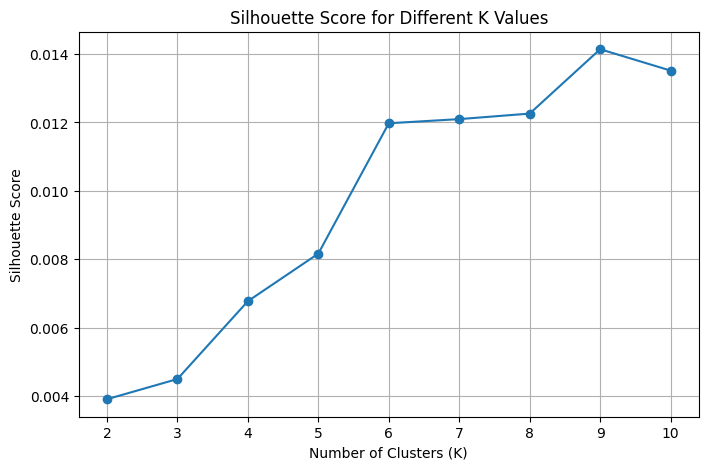

In [105]:
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(K_range)
plt.grid(True)
plt.show()

In [106]:
from sklearn.cluster import KMeans
import pandas as pd

# Test K = 6
kmeans_6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

labels_6 = kmeans_6.fit_predict(X_tfidf)

# Test K = 9
kmeans_9 = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

labels_9 = kmeans_9.fit_predict(X_tfidf)

# Compare cluster sizes
print("Cluster sizes for K = 6:")
print(pd.Series(labels_6).value_counts().sort_index())

print("\nCluster sizes for K = 9:")
print(pd.Series(labels_9).value_counts().sort_index())

Cluster sizes for K = 6:
0     56
1    204
2    223
3     65
4    744
5     21
Name: count, dtype: int64

Cluster sizes for K = 9:
0    157
1     41
2     38
3     21
4    109
5     64
6    204
7    516
8    163
Name: count, dtype: int64


In [107]:
import numpy as np

# Fit the final candidate model for K = 9
kmeans = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_tfidf)

# Get TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

# Display the top terms for each cluster
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

for cluster_num in range(9):
    print(f"\nCluster {cluster_num}:")

    top_terms = [
        feature_names[i]
        for i in order_centroids[cluster_num, :15]
    ]

    print(", ".join(top_terms))
    


Cluster 0:
ticket, tatkal, irctc, booking, not, tatkal ticket, booked, book, help, agent, get, online, booked ticket, refund, counter

Cluster 1:
mumbai, action, taken, action taken, tweet, train, no action, no, wasted ltt, mumbai no, taken station, ltt mumbai, station master, water wasted, master

Cluster 2:
kindly, share, matter, kindly share, concerned, official, look, kindly look, concerned official, number, share number, look matter, forwarded, forwarded concerned, matter forwarded

Cluster 3:
grp, lodged grp, lodged, vide, fir, vide cr, cr, cr no, ipc, fir lodged, no ipc, missing, lodge, no, missing report

Cluster 4:
coach, toilet, water, no, dirty, no water, travelling, water coach, train, cleaning, ac, no coach, water toilet, toilet coach, express

Cluster 5:
working, not working, not, ac, ac not, fan, coach, fan not, working coach, charging, help, train, no, coach ac, point

Cluster 6:
train, late, hour, running, hr, time, running late, no, delayed, delay, train running, lat

In [108]:
for cluster_num in range(9):
    print(f"\n{'=' * 60}")
    print(f"CLUSTER {cluster_num}")
    print('=' * 60)

    samples = df.loc[
        df["cluster"] == cluster_num,
        "clean_text"
    ].head(5)

    for i, complaint in enumerate(samples, start=1):
        print(f"{i}. {complaint}")


CLUSTER 0
1. irctc not responding time tatkal booking
2. reserved ticket allotted rac passenger boarded next station kindly help
3. student's not confirmed ticket counter raeberali denying refund sayin late reach window
4. hi need help wife son hvng waiting ticket ac bilaspur rajhdhani
5. hello want going village no money buy ticket help

CLUSTER 1
1. till no action taken
2. train ticket not comform abu road mumbai mother sick help sirpnr no
3. huge huge scope improve train bathroom extremely dirty spread germ mumbai india
4. really shameful almost train departed source tweet
5. update reviewed not see action taken pl visit take action

CLUSTER 2
1. matter notified concerned official
2. no proper water service train kindly look matter
3. kindly share number contact number
4. matter notified official concerned
5. kindly look

CLUSTER 3
1. fir lodged grp bandikui vide cr no ipc
2. fir lodged grp satna vide cr no ipc transferred grp allahabad
3. said missing person could not traced despi

In [109]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Count the occurrence of words and phrases
count_vectorizer = CountVectorizer(
    max_features=30,
    ngram_range=(1, 2)
)

X_counts = count_vectorizer.fit_transform(df["clean_text"])

# Calculate total frequency for each feature
word_counts = X_counts.sum(axis=0).A1

top_words = pd.DataFrame({
    "Feature": count_vectorizer.get_feature_names_out(),
    "Frequency": word_counts
})

top_words = top_words.sort_values(
    by="Frequency",
    ascending=False
)

print(top_words.to_string(index=False))

    Feature  Frequency
         no        327
      train        300
        not        242
     ticket        229
      water        147
      coach        147
       help        139
       late        120
    railway        107
    station         86
     toilet         76
    working         71
         ac         68
     tatkal         66
       food         64
       time         64
not working         63
       hour         61
    express         58
      irctc         55
  passenger         55
     kindly         51
 travelling         51
        one         50
   no water         49
     action         46
     matter         44
         hr         44
        get         44
     refund         44


In [110]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_new = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.90,
    sublinear_tf=True
)

X_tfidf_new = tfidf_new.fit_transform(df["clean_text"])

print("New TF-IDF matrix shape:", X_tfidf_new.shape)
print("Number of features:", len(tfidf_new.get_feature_names_out()))
print("Non-zero values:", X_tfidf_new.nnz)

New TF-IDF matrix shape: (1313, 2467)
Number of features: 2467
Non-zero values: 13206


In [111]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_range = range(2, 11)
new_silhouette_scores = []

for k in K_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_tfidf_new)

    score = silhouette_score(
        X_tfidf_new,
        labels,
        metric="euclidean"
    )

    new_silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")
    

K = 2, Silhouette Score = 0.0087
K = 3, Silhouette Score = 0.0073
K = 4, Silhouette Score = 0.0098
K = 5, Silhouette Score = 0.0107
K = 6, Silhouette Score = 0.0137
K = 7, Silhouette Score = 0.0130
K = 8, Silhouette Score = 0.0178
K = 9, Silhouette Score = 0.0180
K = 10, Silhouette Score = 0.0204


In [112]:
from sklearn.cluster import KMeans
from collections import Counter

for k in [6, 9, 10]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_tfidf_new)

    print(f"\nCluster sizes for K = {k}:")
    for cluster_id, size in sorted(Counter(labels).items()):
        percentage = (size / len(labels)) * 100
        print(f"Cluster {cluster_id}: {size} complaints ({percentage:.1f}%)")


Cluster sizes for K = 6:
Cluster 0: 58 complaints (4.4%)
Cluster 1: 197 complaints (15.0%)
Cluster 2: 587 complaints (44.7%)
Cluster 3: 66 complaints (5.0%)
Cluster 4: 205 complaints (15.6%)
Cluster 5: 200 complaints (15.2%)

Cluster sizes for K = 9:
Cluster 0: 65 complaints (5.0%)
Cluster 1: 107 complaints (8.1%)
Cluster 2: 188 complaints (14.3%)
Cluster 3: 77 complaints (5.9%)
Cluster 4: 624 complaints (47.5%)
Cluster 5: 162 complaints (12.3%)
Cluster 6: 40 complaints (3.0%)
Cluster 7: 21 complaints (1.6%)
Cluster 8: 29 complaints (2.2%)

Cluster sizes for K = 10:
Cluster 0: 82 complaints (6.2%)
Cluster 1: 484 complaints (36.9%)
Cluster 2: 105 complaints (8.0%)
Cluster 3: 99 complaints (7.5%)
Cluster 4: 66 complaints (5.0%)
Cluster 5: 53 complaints (4.0%)
Cluster 6: 16 complaints (1.2%)
Cluster 7: 178 complaints (13.6%)
Cluster 8: 41 complaints (3.1%)
Cluster 9: 189 complaints (14.4%)


In [113]:
from sklearn.cluster import KMeans

# Fit the K-Means model using refined TF-IDF features
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

# Assign cluster labels to the complaints
df["cluster_10"] = kmeans_10.fit_predict(X_tfidf_new)

# Get feature names from the refined TF-IDF vectorizer
feature_names_new = tfidf_new.get_feature_names_out()

# Identify the top terms for each cluster
order_centroids = kmeans_10.cluster_centers_.argsort()[:, ::-1]

for cluster_num in range(10):
    print(f"\nCluster {cluster_num}:")

    top_terms = [
        feature_names_new[i]
        for i in order_centroids[cluster_num, :15]
    ]

    print(", ".join(top_terms))


Cluster 0:
coach, toilet, dirty, travelling, train, no, cleaning, no coach, ac, seat, clean, toilet coach, express, help, passenger

Cluster 1:
no, food, help, not, thanks, rail, vendor, station, one, need, express, platform, passenger, complaint, reply

Cluster 2:
water, no water, no, toilet, coach, bottle, water toilet, water bottle, train, water coach, selling, traveling, help, supply, tap

Cluster 3:
late, train, hour, running, hr, running late, late hour, hr late, min, hour late, train late, always, no, express, train running

Cluster 4:
working, not working, not, ac, ac not, fan, coach, fan not, working coach, help, charging, train, no, coach ac, point

Cluster 5:
matter, kindly, concerned, share, look, kindly share, official, kindly look, look matter, concerned official, number, forwarded, matter forwarded, share number, forwarded concerned

Cluster 6:
grp, lodged grp, lodged, vide, fir, cr no, fir lodged, cr, ipc, vide cr, no ipc, no, transferred grp, transferred, ipc transfer

In [114]:
# Display five sample complaints from each K = 10 cluster

for cluster_num in range(10):
    print(f"\n{'=' * 60}")
    print(f"CLUSTER {cluster_num}")
    print('=' * 60)

    samples = df.loc[
        df["cluster_10"] == cluster_num,
        "clean_text"
    ].head(5)

    for i, complaint in enumerate(samples, start=1):
        print(f"{i}. {complaint}")


CLUSTER 0
1. traveling chennai train coach berth dirty one vomitted birth
2. travelling howrah cuttack jan shatabdi exp no cleanliness coach
3. pathetic dirty toilet bilaspur hapa express help
4. parent travelling no coach
5. coach tt accepted bribe allotted seat l passenger instead rac seat

CLUSTER 1
1. can't give justice graduate engineer one thing least stop recruiting tech sse
2. enter win amazon gift card book urbanfantasy romance
3. update status today ltt ppta express departure ltt
4. google button used billion time day source alltwitter
5. dear father senior citizen patient travelling alone seat not confirmed rac

CLUSTER 2
1. way no water toilet mess everywhere coach provide basic facil
2. dirty water flowing ftm blower local coach aft rain thane vashi
3. still vendor selling local local product like water etc inside train
4. swatch bharat abhiyaan train stop kozhikod calicut no one come no water
5. water point

CLUSTER 3
1. update today intercity late min
2. emu ghaziabad n

In [115]:
# Map cluster IDs to descriptive names
cluster_names = {
    0: "Coach Cleanliness and Facilities",
    1: "Miscellaneous Railway Complaints",
    2: "Water Supply and Basic Amenities",
    3: "Train Delays",
    4: "Equipment and Service Malfunctions",
    5: "Complaint Escalation and Official Responses",
    6: "Railway Police and FIR Matters",
    7: "General Railway Service Issues",
    8: "Action Requests and Complaint Follow-ups",
    9: "Ticket Booking and Reservation Problems"
}

# Create a column containing the cluster names
df["cluster_name"] = df["cluster_10"].map(cluster_names)

# Display sample results
df[["SentimentText", "cluster_10", "cluster_name"]].head(10)

,SentimentText,cluster_10,cluster_name
0,i am in way but there is no water in toilet an...,2,Water Supply and Basic Amenities
1,ac not working in prayag lucknow intercity tod...,4,Equipment and Service Malfunctions
2,i'm traveling to chennai by train coach s4 my ...,0,Coach Cleanliness and Facilities
3,irctc is not responding at the time of tatkal ...,9,Ticket Booking and Reservation Problems
4,matter notified to concerned official,5,Complaint Escalation and Official Responses
5,if you can't give justice to graduate engineer...,1,Miscellaneous Railway Complaints
6,wrkout smthng tht cn hlp trains to run on righ...,7,General Railway Service Issues
7,dirty water flowing ftm blower of local coach ...,2,Water Supply and Basic Amenities
8,enter to win amazon gift card books urbanfanta...,1,Miscellaneous Railway Complaints
9,still vendors are selling local local products...,2,Water Supply and Basic Amenities


In [116]:
cluster_summary = (
    df.groupby(["cluster_10", "cluster_name"])
      .size()
      .reset_index(name="complaint_count")
      .sort_values("cluster_10")
)

cluster_summary

,cluster_10,cluster_name,complaint_count
0,0,Coach Cleanliness and Facilities,82
1,1,Miscellaneous Railway Complaints,484
2,2,Water Supply and Basic Amenities,105
3,3,Train Delays,99
4,4,Equipment and Service Malfunctions,66
5,5,Complaint Escalation and Official Responses,53
6,6,Railway Police and FIR Matters,16
7,7,General Railway Service Issues,178
8,8,Action Requests and Complaint Follow-ups,41
9,9,Ticket Booking and Reservation Problems,189


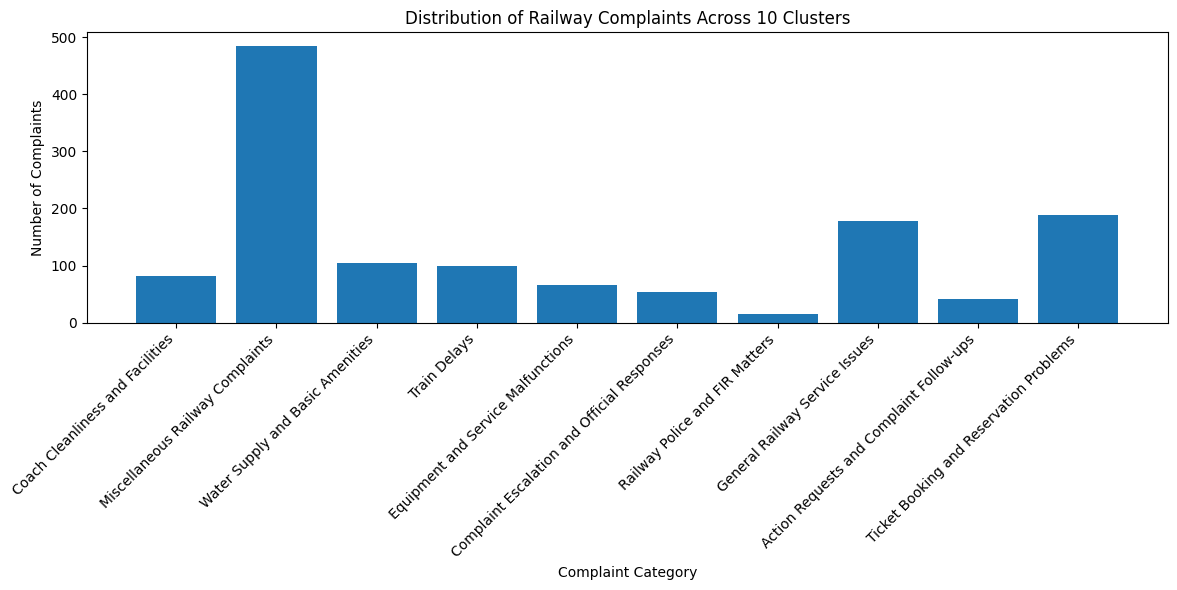

In [117]:
import matplotlib.pyplot as plt

# Prepare cluster summary
cluster_summary = (
    df.groupby(["cluster_10", "cluster_name"])
      .size()
      .reset_index(name="complaint_count")
      .sort_values("cluster_10")
)

# Plot cluster distribution
plt.figure(figsize=(12, 6))

plt.bar(
    cluster_summary["cluster_name"],
    cluster_summary["complaint_count"]
)

plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.title("Distribution of Railway Complaints Across 10 Clusters")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [118]:

def preprocess_text(text):
    if not isinstance(text, str):
        return ""

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # 3. Remove mentions
    text = re.sub(r"@\w+", " ", text)

    # 4. Remove retweet markers
    text = re.sub(r"\brt\b", " ", text)

    # 5. Preserve hashtag words
    text = re.sub(r"#(\w+)", r"\1", text)

    # 6. Remove punctuation and unwanted symbols
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # 7. Tokenize
    tokens = word_tokenize(text)

    # 8. Normalize abbreviations using your existing dictionary
    tokens = [slang_map.get(word, word) for word in tokens]

    # 9. Remove stopwords while preserving negations
    tokens = [
        word for word in tokens
        if word not in custom_stopwords
        or word in {"no", "not", "nor", "never"}
    ]

    # 10. Lemmatize
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # 11. Return cleaned text
    return " ".join(tokens)


In [120]:
test_complaint = "The AC is not working in my train coach!"

cleaned_complaint = preprocess_text(test_complaint)

print("Original complaint:", test_complaint)
print("Cleaned complaint:", cleaned_complaint)

NameError: name 'word_tokenize' is not defined

In [ ]:
def predict_complaint(complaint):
    cleaned_complaint = preprocess_text(complaint)

    if not cleaned_complaint.strip():
        print("Please enter a valid complaint.")
        return None

    complaint_vector = tfidf_new.transform([cleaned_complaint])

    predicted_cluster = kmeans_10.predict(complaint_vector)[0]

    predicted_category = cluster_names[predicted_cluster]

    print("Original Complaint:", complaint)
    print("Cleaned Complaint:", cleaned_complaint)
    print("Predicted Cluster:", predicted_cluster)
    print("Predicted Category:", predicted_category)

    return predicted_category

In [ ]:
predict_complaint("The AC in my train coach is not working")

In [ ]:
test_complaints = [
    "There is no water in the train toilet",
    "My train is running three hours late",
    "I cannot book a Tatkal ticket on IRCTC",
    "The coach and toilet are very dirty",
    "I have lodged an FIR with the railway police",
    "The railway officials have not taken any action",
    "The fan in my coach is not working",
    "I want a refund for my cancelled ticket"
]

for complaint in test_complaints:
    print("\n" + "=" * 60)
    predict_complaint(complaint)


In [ ]:

additional_complaints = [
    "FIR lodged with GRP at the railway station",
    "The railway police have registered my complaint",
    "My train is delayed by two hours",
    "There is no drinking water in my coach",
    "The toilet in the train is dirty",
    "My Tatkal ticket booking failed",
    "The AC and fan are not working",
    "Railway officials have taken no action on my complaint"
]

for complaint in additional_complaints:
    print("\n" + "=" * 60)
    predict_complaint(complaint)


In [ ]:
print("TF-IDF Vectorizer:", type(tfidf_new))
print("K-Means Model:", type(kmeans_10))
print("Cluster Names:", type(cluster_names))

print("Number of clusters:", kmeans_10.n_clusters)
print("Number of TF-IDF features:", len(tfidf_new.get_feature_names_out()))
print("Model input features:", kmeans_10.n_features_in_)

In [ ]:
%whos

In [ ]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())